In [1]:
# 1. Load Cleaned Dataset with Date Parsing

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify project root
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "data" / "processed").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "processed").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("Could not locate processed data folder.")

# Dataset path
CLEAN_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "superstore_cleaned.csv"
)

# Load dataset with date parsing
df = pd.read_csv(
    CLEAN_PATH,
    encoding="utf-8-sig",
    parse_dates=["order_date", "ship_date"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nDate column data types:")
print(df[["order_date", "ship_date"]].dtypes)

print("\nOrder Date Range:")
print("Start:", df["order_date"].min())
print("End:", df["order_date"].max())

print("\nShip Date Range:")
print("Start:", df["ship_date"].min())
print("End:", df["ship_date"].max())

display(df.head())

Dataset loaded successfully!
Dataset shape: (51290, 24)

Date column data types:
order_date    datetime64[ns]
ship_date     datetime64[ns]
dtype: object

Order Date Range:
Start: 2011-01-01 00:00:00
End: 2014-12-31 00:00:00

Ship Date Range:
Start: 2011-01-03 00:00:00
End: 2015-01-07 00:00:00


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,...,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority
0,42433,AG-2011-2040,2011-01-01,2011-01-06,standard class,TB-11280,Toby Braunhardt,consumer,constantine,constantine,...,OFF-TEN-10000025,office supplies,storage,"Tenex Lockers, Blue",408.300,2,0.0,106.140,35.46,medium
1,22253,IN-2011-47883,2011-01-01,2011-01-08,standard class,JH-15985,Joseph Holt,consumer,wagga wagga,new south wales,...,OFF-SU-10000618,office supplies,supplies,"Acme Trimmer, High Speed",120.366,3,0.1,36.036,9.72,medium
2,48883,HU-2011-1220,2011-01-01,2011-01-05,second class,AT-735,Annie Thurman,consumer,budapest,budapest,...,OFF-TEN-10001585,office supplies,storage,"Tenex Box, Single Width",66.120,4,0.0,29.640,8.17,high
3,11731,IT-2011-3647632,2011-01-01,2011-01-05,second class,EM-14140,Eugene Moren,home office,stockholm,stockholm,...,OFF-PA-10001492,office supplies,paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.055,4.82,high
4,22255,IN-2011-47883,2011-01-01,2011-01-08,standard class,JH-15985,Joseph Holt,consumer,wagga wagga,new south wales,...,FUR-FU-10003447,furniture,furnishings,"Eldon Light Bulb, Duo Pack",113.670,5,0.1,37.770,4.70,medium


In [2]:
# 2. Date Validation and Shipping Duration Analysis

# Calculate shipping duration in days
df["shipping_duration"] = (
    df["ship_date"] - df["order_date"]
).dt.days

# Date validation checks
print("DATE VALIDATION")
print("-" * 45)

print("Missing order dates:", df["order_date"].isna().sum())
print("Missing ship dates:", df["ship_date"].isna().sum())

print(
    "Ship dates before order dates:",
    (df["ship_date"] < df["order_date"]).sum()
)

print(
    "Negative shipping durations:",
    (df["shipping_duration"] < 0).sum()
)

print("\nSHIPPING DURATION STATISTICS")
print("-" * 45)

print("Average shipping duration:",
      round(df["shipping_duration"].mean(), 2), "days")

print("Median shipping duration:",
      df["shipping_duration"].median(), "days")

print("Minimum shipping duration:",
      df["shipping_duration"].min(), "days")

print("Maximum shipping duration:",
      df["shipping_duration"].max(), "days")

print("\nShipping duration distribution:")
display(df["shipping_duration"].describe())

DATE VALIDATION
---------------------------------------------
Missing order dates: 0
Missing ship dates: 0
Ship dates before order dates: 0
Negative shipping durations: 0

SHIPPING DURATION STATISTICS
---------------------------------------------
Average shipping duration: 3.97 days
Median shipping duration: 4.0 days
Minimum shipping duration: 0 days
Maximum shipping duration: 7 days

Shipping duration distribution:


count    51290.000000
mean         3.969370
std          1.729437
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max          7.000000
Name: shipping_duration, dtype: float64

In [3]:
# 3. Yearly Sales Performance Analysis

# Extract year from order date
df["year"] = df["order_date"].dt.year

# Calculate yearly KPIs
yearly_analysis = df.groupby("year").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    total_quantity=("quantity", "sum"),
    total_orders=("order_id", "nunique"),
    total_customers=("customer_id", "nunique")
).reset_index()

# Calculate profit margin and average order value
yearly_analysis["profit_margin"] = (
    yearly_analysis["total_profit"]
    / yearly_analysis["total_sales"]
) * 100

yearly_analysis["average_order_value"] = (
    yearly_analysis["total_sales"]
    / yearly_analysis["total_orders"]
)

# Format results
yearly_analysis = yearly_analysis.round(2)

display(yearly_analysis)


,year,total_sales,total_profit,total_quantity,total_orders,total_customers,profit_margin,average_order_value
0,2011,2259450.90,248940.81,31443,4440,1309,11.02,508.89
1,2012,2677438.69,307415.28,38111,5343,1373,11.48,501.11
2,2013,3405746.45,406935.23,48136,6721,1458,11.95,506.73
3,2014,4299865.87,504165.97,60622,8531,1511,11.73,504.03


In [4]:
# 4. Year-over-Year (YoY) Growth Analysis

yearly_growth = yearly_analysis[
    ["year", "total_sales", "total_profit", "total_orders", "total_quantity"]
].copy()

# Calculate percentage growth
for column in [
    "total_sales",
    "total_profit",
    "total_orders",
    "total_quantity"
]:
    yearly_growth[f"{column}_growth_%"] = (
        yearly_growth[column].pct_change() * 100
    )

yearly_growth = yearly_growth.round(2)

display(yearly_growth)

,year,total_sales,total_profit,total_orders,total_quantity,total_sales_growth_%,total_profit_growth_%,total_orders_growth_%,total_quantity_growth_%
0,2011,2259450.90,248940.81,4440,31443,NaN,NaN,NaN,NaN
1,2012,2677438.69,307415.28,5343,38111,18.50,23.49,20.34,21.21
2,2013,3405746.45,406935.23,6721,48136,27.20,32.37,25.79,26.30
3,2014,4299865.87,504165.97,8531,60622,26.25,23.89,26.93,25.94


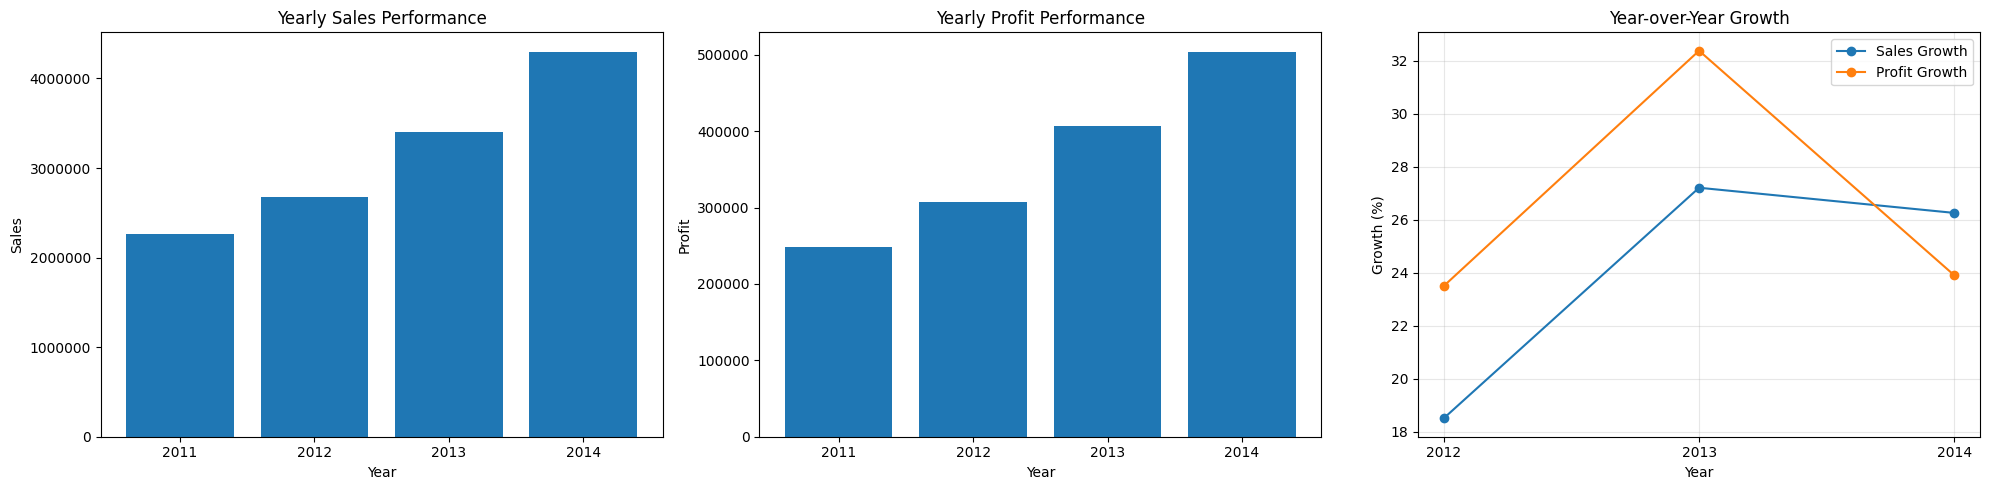

In [5]:
# 5. Yearly Business Performance Visualization

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Yearly Sales
axes[0].bar(
    yearly_analysis["year"].astype(str),
    yearly_analysis["total_sales"]
)
axes[0].set_title("Yearly Sales Performance")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sales")
axes[0].ticklabel_format(axis="y", style="plain")

# Yearly Profit
axes[1].bar(
    yearly_analysis["year"].astype(str),
    yearly_analysis["total_profit"]
)
axes[1].set_title("Yearly Profit Performance")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Profit")
axes[1].ticklabel_format(axis="y", style="plain")

# Yearly Sales vs Profit Growth
axes[2].plot(
    yearly_growth["year"].astype(str),
    yearly_growth["total_sales_growth_%"],
    marker="o",
    label="Sales Growth"
)

axes[2].plot(
    yearly_growth["year"].astype(str),
    yearly_growth["total_profit_growth_%"],
    marker="o",
    label="Profit Growth"
)

axes[2].set_title("Year-over-Year Growth")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Growth (%)")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# 6. Quarterly Sales and Profit Analysis

# Extract quarter from order date
df["quarter"] = df["order_date"].dt.quarter

# Aggregate quarterly performance
quarterly_analysis = df.groupby("quarter").agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    total_quantity=("quantity", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

# Add quarter labels
quarterly_analysis["quarter"] = (
    "Q" + quarterly_analysis["quarter"].astype(str)
)

# Calculate profit margin and average order value
quarterly_analysis["profit_margin"] = (
    quarterly_analysis["total_profit"]
    / quarterly_analysis["total_sales"]
) * 100

quarterly_analysis["average_order_value"] = (
    quarterly_analysis["total_sales"]
    / quarterly_analysis["total_orders"]
)

quarterly_analysis = quarterly_analysis.round(2)

display(quarterly_analysis)

,quarter,total_sales,total_profit,total_quantity,total_orders,profit_margin,average_order_value
0,Q1,1989373.99,238555.10,26605,3913,11.99,508.40
1,Q2,2872290.30,325102.83,41713,6036,11.32,475.86
2,Q3,3480595.11,400362.38,49137,7038,11.50,494.54
3,Q4,4300242.50,503436.97,60857,8561,11.71,502.31


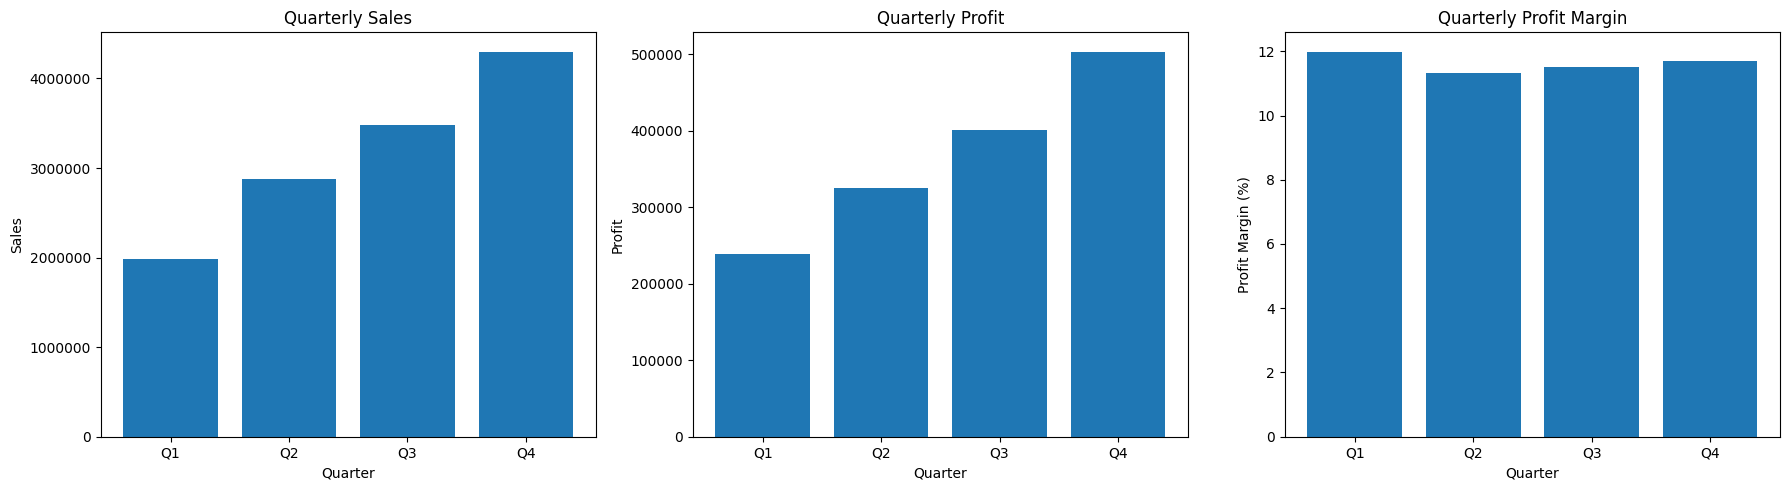

In [7]:
# 7. Quarterly Performance Visualization

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Quarterly Sales
axes[0].bar(
    quarterly_analysis["quarter"],
    quarterly_analysis["total_sales"]
)
axes[0].set_title("Quarterly Sales")
axes[0].set_xlabel("Quarter")
axes[0].set_ylabel("Sales")
axes[0].ticklabel_format(axis="y", style="plain")

# Quarterly Profit
axes[1].bar(
    quarterly_analysis["quarter"],
    quarterly_analysis["total_profit"]
)
axes[1].set_title("Quarterly Profit")
axes[1].set_xlabel("Quarter")
axes[1].set_ylabel("Profit")
axes[1].ticklabel_format(axis="y", style="plain")

# Quarterly Profit Margin
axes[2].bar(
    quarterly_analysis["quarter"],
    quarterly_analysis["profit_margin"]
)
axes[2].set_title("Quarterly Profit Margin")
axes[2].set_xlabel("Quarter")
axes[2].set_ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

In [8]:
# 8. Year-wise Quarterly Sales Analysis

yearly_quarterly_sales = df.pivot_table(
    index="year",
    columns="quarter",
    values="sales",
    aggfunc="sum"
)

yearly_quarterly_sales.columns = [
    f"Q{quarter}" for quarter in yearly_quarterly_sales.columns
]

display(yearly_quarterly_sales.round(2))

,Q1,Q2,Q3,Q4
year,,,,
2011,335780.01,478870.98,613306.37,831493.54
2012,399367.71,625592.86,737768.89,914709.23
2013,565019.59,834839.49,933036.99,1072850.38
2014,689206.68,932986.97,1196482.87,1481189.35


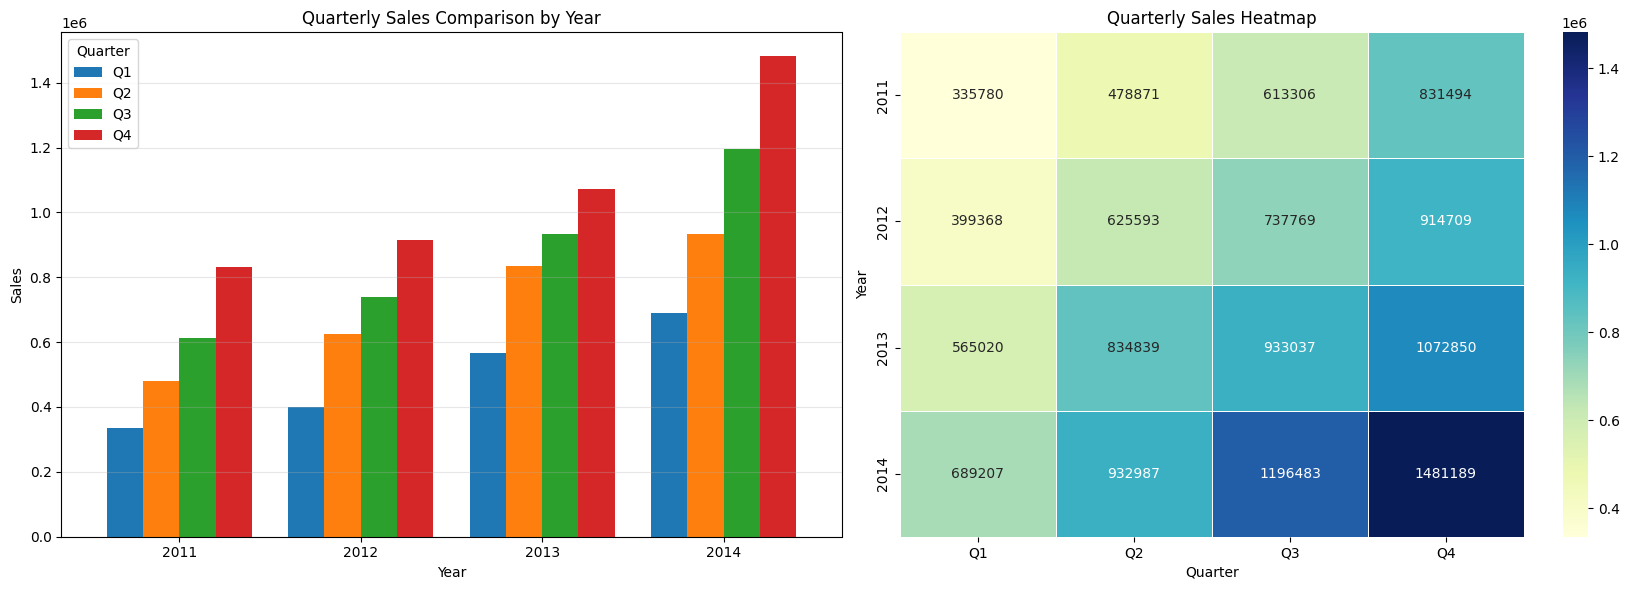

In [9]:
# 9. Year-wise Quarterly Sales Visualization

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Grouped bar chart
yearly_quarterly_sales.plot(
    kind="bar",
    ax=axes[0],
    width=0.8
)

axes[0].set_title("Quarterly Sales Comparison by Year")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sales")
axes[0].legend(title="Quarter")
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

# Heatmap
sns.heatmap(
    yearly_quarterly_sales,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title("Quarterly Sales Heatmap")
axes[1].set_xlabel("Quarter")
axes[1].set_ylabel("Year")

plt.tight_layout()
plt.show()

In [10]:
# 10. Monthly Sales and Profit Analysis

# Extract month number and month name
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.month_name()

# Aggregate monthly performance across all years
monthly_analysis = df.groupby(
    ["month", "month_name"]
).agg(
    total_sales=("sales", "sum"),
    total_profit=("profit", "sum"),
    total_quantity=("quantity", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

# Calculate additional KPIs
monthly_analysis["profit_margin"] = (
    monthly_analysis["total_profit"]
    / monthly_analysis["total_sales"]
) * 100

monthly_analysis["average_order_value"] = (
    monthly_analysis["total_sales"]
    / monthly_analysis["total_orders"]
)

monthly_analysis = monthly_analysis.round(2)

display(monthly_analysis)

,month,month_name,total_sales,total_profit,total_quantity,total_orders,profit_margin,average_order_value
0,1,January,675133.67,73535.38,8843,1271,10.89,531.18
1,2,February,543739.38,70932.20,7281,1104,13.05,492.52
2,3,March,770500.94,94087.52,10481,1555,12.21,495.50
3,4,April,698561.21,73513.63,10552,1506,10.52,463.85
4,5,May,904012.34,104509.78,13042,1897,11.56,476.55
5,6,June,1269716.75,147079.42,18119,2662,11.58,476.98
6,7,July,749381.84,78070.09,10984,1561,10.42,480.07
7,8,August,1293833.17,151854.11,17611,2500,11.74,517.53
8,9,September,1437380.11,170438.18,20542,3021,11.86,475.80
9,10,October,1168184.39,157269.36,16049,2290,13.46,510.12


In [11]:
# 11. Best and Worst Performing Months

metrics = [
    "total_sales",
    "total_profit",
    "total_orders",
    "profit_margin"
]

for metric in metrics:

    best_month = monthly_analysis.loc[
        monthly_analysis[metric].idxmax()
    ]

    worst_month = monthly_analysis.loc[
        monthly_analysis[metric].idxmin()
    ]

    print(f"\n{metric.upper().replace('_', ' ')}")
    print("-" * 45)

    print(
        f"Best Month: {best_month['month_name']} "
        f"({best_month[metric]:,.2f})"
    )

    print(
        f"Worst Month: {worst_month['month_name']} "
        f"({worst_month[metric]:,.2f})"
    )


TOTAL SALES
---------------------------------------------
Best Month: December (1,580,780.77)
Worst Month: February (543,739.38)

TOTAL PROFIT
---------------------------------------------
Best Month: November (175,449.48)
Worst Month: February (70,932.20)

TOTAL ORDERS
---------------------------------------------
Best Month: December (3,166.00)
Worst Month: February (1,104.00)

PROFIT MARGIN
---------------------------------------------
Best Month: October (13.46)
Worst Month: July (10.42)


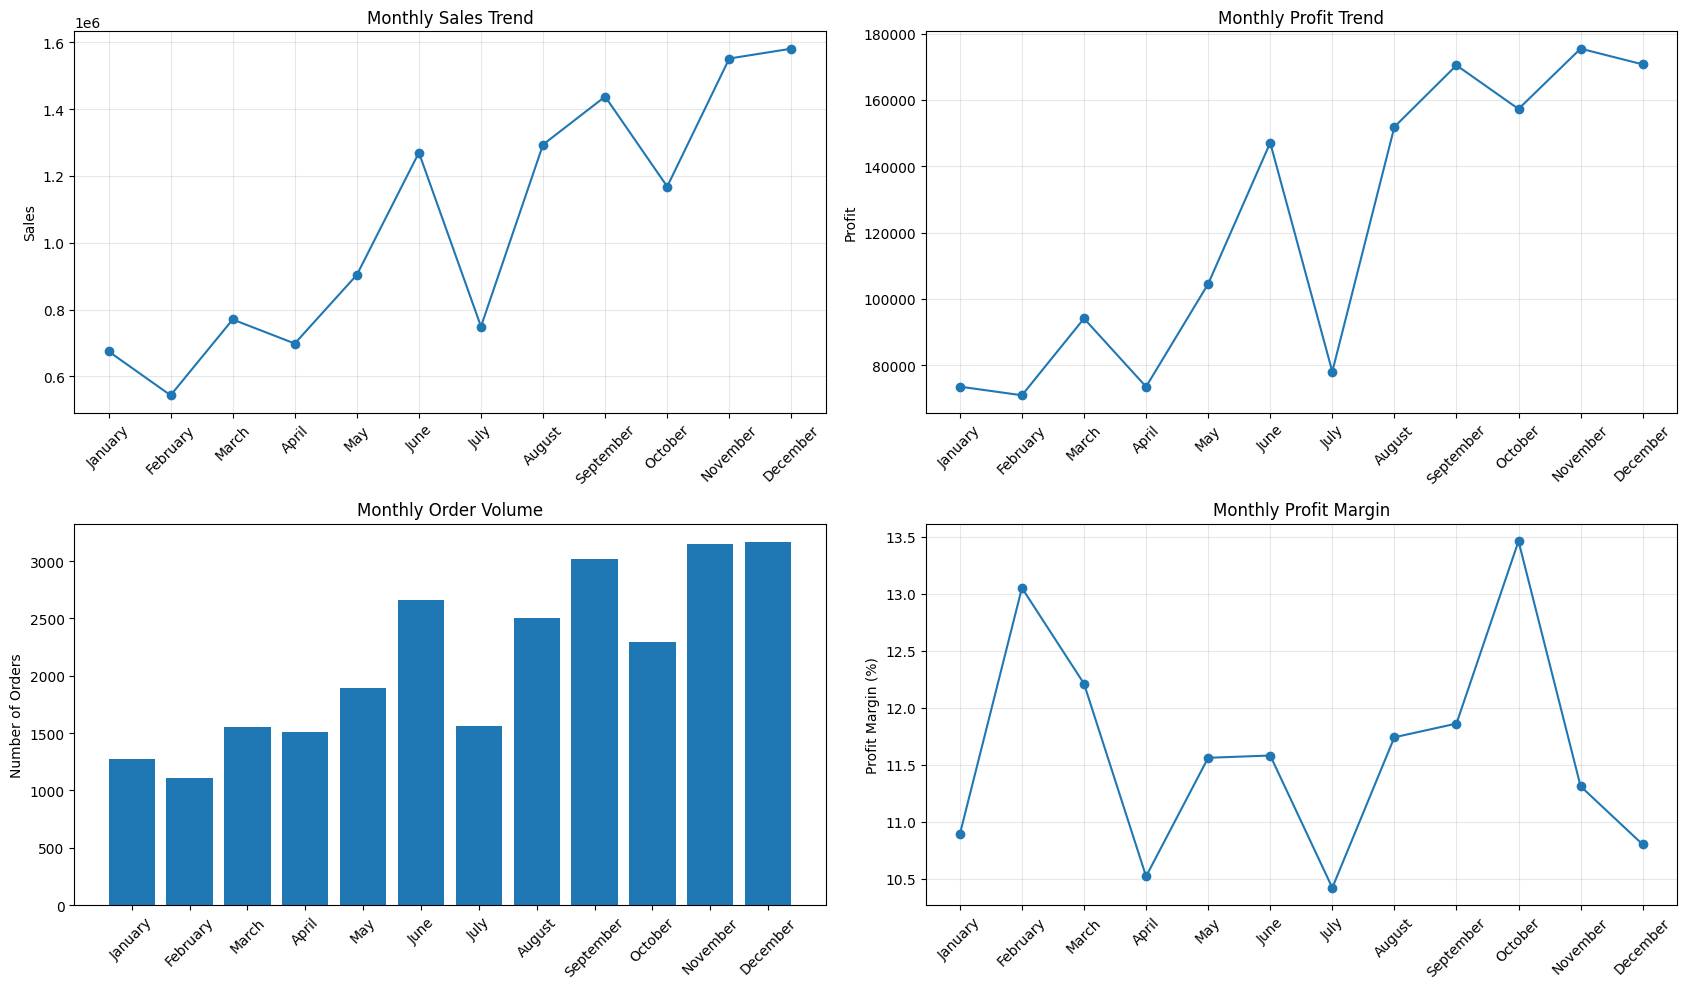

In [12]:
# 12. Monthly Sales and Profit Visualization

fig, axes = plt.subplots(2, 2, figsize=(17, 10))

# Monthly Sales
axes[0, 0].plot(
    monthly_analysis["month_name"],
    monthly_analysis["total_sales"],
    marker="o"
)
axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].set_ylabel("Sales")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(alpha=0.3)

# Monthly Profit
axes[0, 1].plot(
    monthly_analysis["month_name"],
    monthly_analysis["total_profit"],
    marker="o"
)
axes[0, 1].set_title("Monthly Profit Trend")
axes[0, 1].set_ylabel("Profit")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].grid(alpha=0.3)

# Monthly Order Volume
axes[1, 0].bar(
    monthly_analysis["month_name"],
    monthly_analysis["total_orders"]
)
axes[1, 0].set_title("Monthly Order Volume")
axes[1, 0].set_ylabel("Number of Orders")
axes[1, 0].tick_params(axis="x", rotation=45)

# Monthly Profit Margin
axes[1, 1].plot(
    monthly_analysis["month_name"],
    monthly_analysis["profit_margin"],
    marker="o"
)
axes[1, 1].set_title("Monthly Profit Margin")
axes[1, 1].set_ylabel("Profit Margin (%)")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
# 13. Year-wise Monthly Sales Analysis

yearly_monthly_sales = df.pivot_table(
    index="year",
    columns="month_name",
    values="sales",
    aggfunc="sum"
)

# Ensure chronological month order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

yearly_monthly_sales = yearly_monthly_sales[month_order]

display(yearly_monthly_sales.round(2))

month_name,January,February,March,April,May,June,July,August,September,October,November,December
year,,,,,,,,,,,,
2011,98898.49,91152.16,145729.37,116915.76,146747.84,215207.38,115510.42,207581.49,290214.46,199071.26,298496.54,333925.73
2012,135780.72,100510.22,163076.77,161052.27,208364.89,256175.70,145236.79,303142.94,289389.17,252939.85,323512.42,338256.97
2013,199185.91,167239.65,198594.03,177821.32,260498.56,396519.61,229928.95,326488.79,376619.25,293406.64,373989.36,405454.38
2014,241268.56,184837.36,263100.77,242771.86,288401.05,401814.06,258705.68,456619.94,481157.24,422766.63,555279.03,503143.69


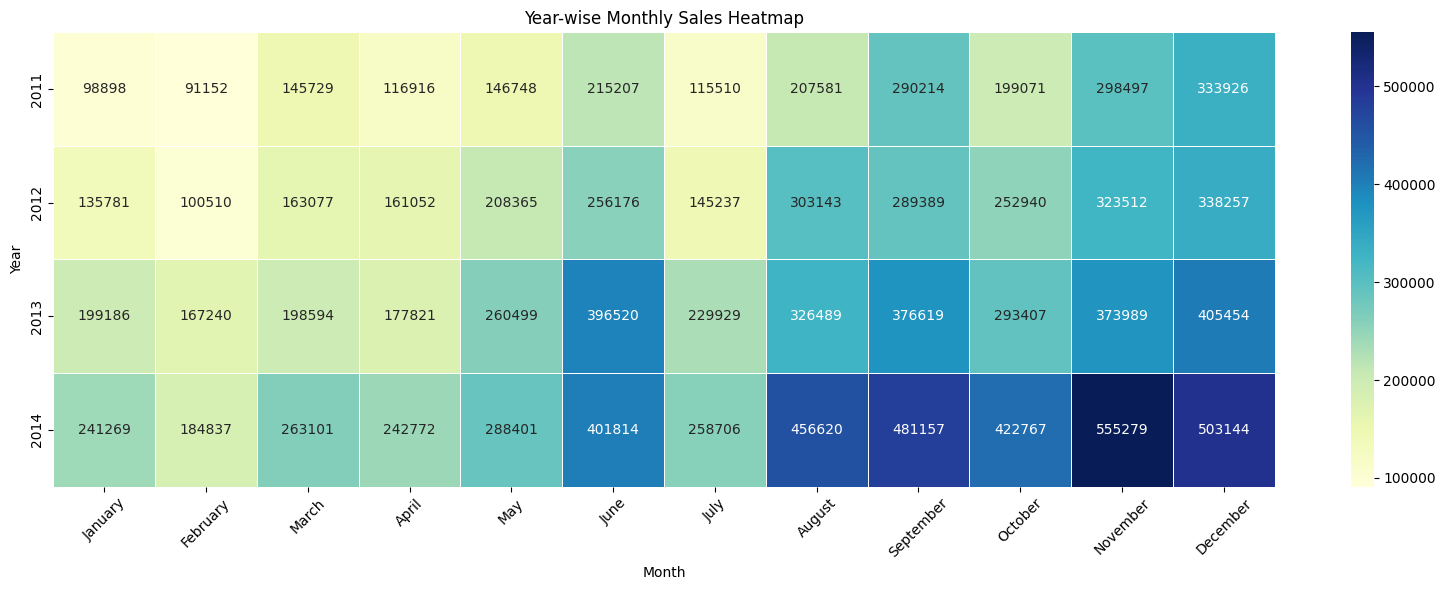

In [14]:
# 14. Monthly Sales Seasonality Heatmap

plt.figure(figsize=(16, 6))

sns.heatmap(
    yearly_monthly_sales,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Year-wise Monthly Sales Heatmap")
plt.xlabel("Month")
plt.ylabel("Year")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [15]:
# 15. Month-wise Year-over-Year Sales Growth

monthly_yoy = df.groupby(
    ["year", "month"]
)["sales"].sum().reset_index()

# Calculate growth compared with the same month in the previous year
monthly_yoy["sales_growth_%"] = (
    monthly_yoy.groupby("month")["sales"]
    .pct_change() * 100
)

# Convert month numbers to names
monthly_yoy["month_name"] = pd.to_datetime(
    monthly_yoy["month"], format="%m"
).dt.month_name()

# Create comparison table
monthly_yoy_pivot = monthly_yoy.pivot(
    index="month_name",
    columns="year",
    values="sales_growth_%"
)

monthly_yoy_pivot = monthly_yoy_pivot.reindex(month_order)

display(monthly_yoy_pivot.round(2))

year,2011,2012,2013,2014
month_name,,,,
January,NaN,37.29,46.70,21.13
February,NaN,10.27,66.39,10.52
March,NaN,11.90,21.78,32.48
April,NaN,37.75,10.41,36.53
May,NaN,41.99,25.02,10.71
June,NaN,19.04,54.78,1.34
July,NaN,25.73,58.31,12.52
August,NaN,46.04,7.70,39.86
September,NaN,-0.28,30.14,27.76


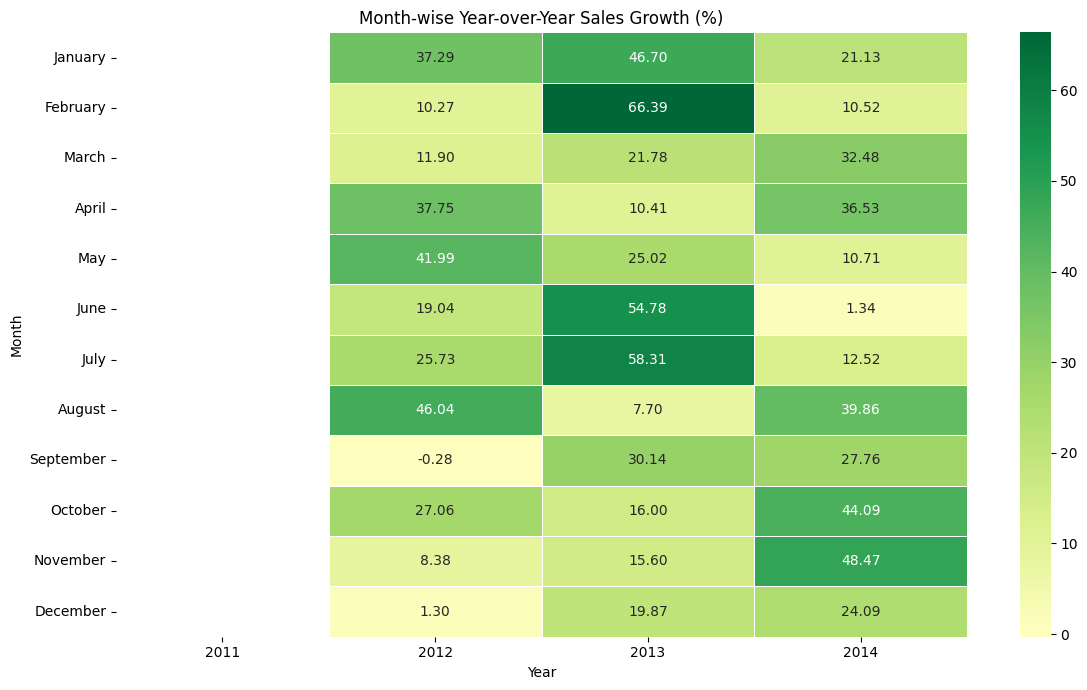

In [16]:
# 16. Monthly Year-over-Year Growth Heatmap

plt.figure(figsize=(12, 7))

sns.heatmap(
    monthly_yoy_pivot,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5
)

plt.title("Month-wise Year-over-Year Sales Growth (%)")
plt.xlabel("Year")
plt.ylabel("Month")

plt.tight_layout()
plt.show()

In [17]:
# 17. Average Monthly Sales Across Four Years

monthly_average = df.groupby("month_name").agg(
    average_sales=("sales", "sum"),
    average_profit=("profit", "sum")
).reset_index()

monthly_average["average_sales"] /= 4
monthly_average["average_profit"] /= 4

monthly_average = monthly_average.round(2)

display(monthly_average)

,month_name,average_sales,average_profit
0,April,174640.30,18378.41
1,August,323458.29,37963.53
2,December,395195.19,42679.53
3,February,135934.84,17733.05
4,January,168783.42,18383.85
5,July,187345.46,19517.52
6,June,317429.19,36769.85
7,March,192625.24,23521.88
8,May,226003.08,26127.45
9,November,387819.34,43862.37


In [18]:
# 18. Average Monthly Performance Across Four Years

monthly_average = df.groupby("month").agg(
    average_sales=("sales", "sum"),
    average_profit=("profit", "sum"),
    average_orders=("order_id", "nunique")
).reset_index()

# Calculate average annual monthly performance
monthly_average["average_sales"] /= 4
monthly_average["average_profit"] /= 4
monthly_average["average_orders"] /= 4

# Add month names in chronological order
monthly_average["month_name"] = pd.to_datetime(
    monthly_average["month"], format="%m"
).dt.month_name()

monthly_average = monthly_average.round(2)

display(monthly_average)

,month,average_sales,average_profit,average_orders,month_name
0,1,168783.42,18383.85,317.75,January
1,2,135934.84,17733.05,276.00,February
2,3,192625.24,23521.88,388.75,March
3,4,174640.30,18378.41,376.50,April
4,5,226003.08,26127.45,474.25,May
5,6,317429.19,36769.85,665.50,June
6,7,187345.46,19517.52,390.25,July
7,8,323458.29,37963.53,625.00,August
8,9,359345.03,42609.55,755.25,September
9,10,292046.10,39317.34,572.50,October


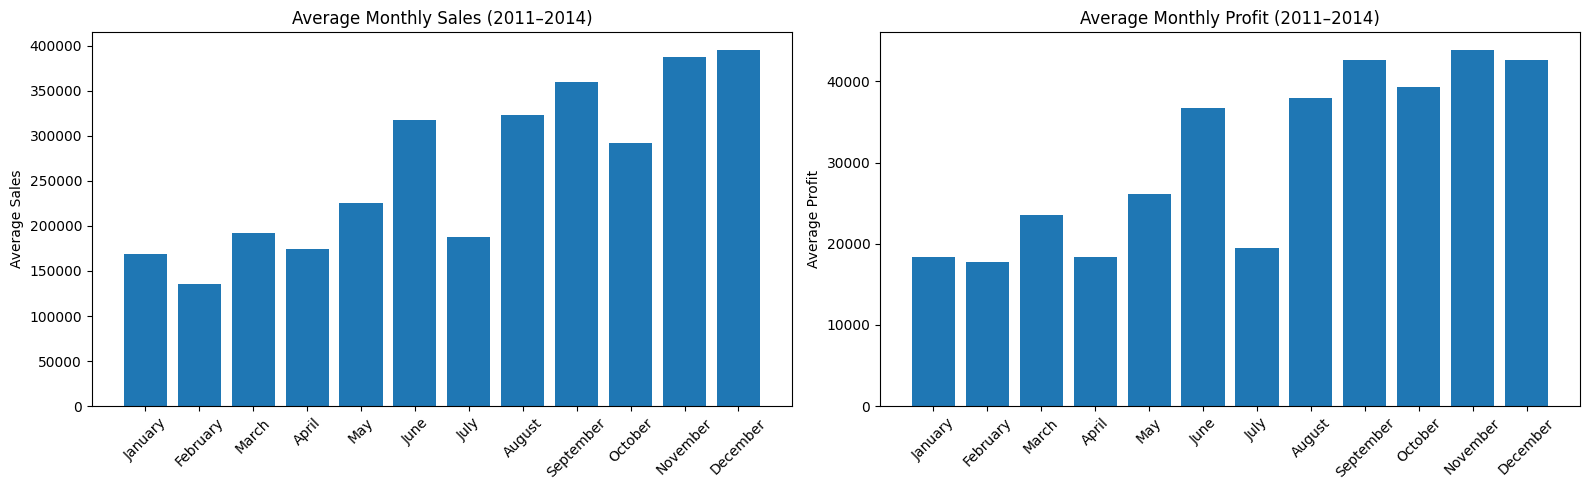

In [19]:
# 19. Average Monthly Sales and Profit Visualization

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Average monthly sales
axes[0].bar(
    monthly_average["month_name"],
    monthly_average["average_sales"]
)

axes[0].set_title("Average Monthly Sales (2011–2014)")
axes[0].set_ylabel("Average Sales")
axes[0].tick_params(axis="x", rotation=45)

# Average monthly profit
axes[1].bar(
    monthly_average["month_name"],
    monthly_average["average_profit"]
)

axes[1].set_title("Average Monthly Profit (2011–2014)")
axes[1].set_ylabel("Average Profit")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [20]:
# 20. Monthly Average Order Value Analysis

monthly_average["average_order_value"] = (
    monthly_average["average_sales"]
    / monthly_average["average_orders"]
)

monthly_average["average_order_value"] = (
    monthly_average["average_order_value"].round(2)
)

display(
    monthly_average[
        ["month_name", "average_orders", "average_order_value"]
    ]
)

# Identify highest and lowest AOV months
best_aov = monthly_average.loc[
    monthly_average["average_order_value"].idxmax()
]

worst_aov = monthly_average.loc[
    monthly_average["average_order_value"].idxmin()
]

print("\nHIGHEST AVERAGE ORDER VALUE")
print(best_aov["month_name"], best_aov["average_order_value"])

print("\nLOWEST AVERAGE ORDER VALUE")
print(worst_aov["month_name"], worst_aov["average_order_value"])

,month_name,average_orders,average_order_value
0,January,317.75,531.18
1,February,276.00,492.52
2,March,388.75,495.50
3,April,376.50,463.85
4,May,474.25,476.55
5,June,665.50,476.98
6,July,390.25,480.07
7,August,625.00,517.53
8,September,755.25,475.80
9,October,572.50,510.12



HIGHEST AVERAGE ORDER VALUE
January 531.18

LOWEST AVERAGE ORDER VALUE
April 463.85


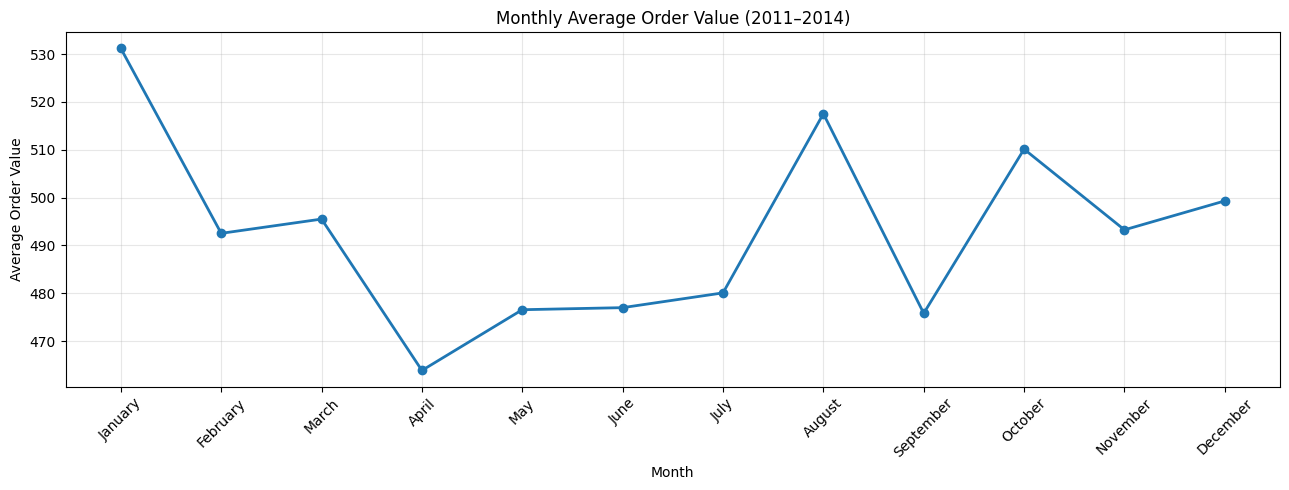

In [21]:
# 21. Monthly Average Order Value Visualization

fig, ax1 = plt.subplots(figsize=(13, 5))

# Average Order Value
ax1.plot(
    monthly_average["month_name"],
    monthly_average["average_order_value"],
    marker="o",
    linewidth=2,
    label="Average Order Value"
)

ax1.set_title("Monthly Average Order Value (2011–2014)")
ax1.set_xlabel("Month")
ax1.set_ylabel("Average Order Value")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(alpha=0.3)

plt.tight_layout()
plt.show()